# Enge dataset: preprocessing 


In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import anndata
seed=0

In [3]:
safe = ['#88CCEE','#CC6677', '#DDCC77','#117733','#332288','#AA4499','#44AA99','#999933','#882255','#661100','#6699CC','#888888']
bold_and_vivid = ['#7F3C8D','#11A579','#3969AC','#F2B701','#E73F74','#80BA5A','#E68310','#008695','#CF1C90',
           '#f97b72','#4b4b8f', '#E58606','#5D69B1','#52BCA3','#99C945','#CC61B0','#24796C','#DAA51B',
           '#2F8AC4','#764E9F','#ED645A','#CC3A8E']

# Start from GSM .csv files (downloaded from GEO)
Cells are provided as separate files and we need to merge all the files to obtain a single gene x cell matrix of the whole dataset. 

In [29]:
path2gsm = '../../data/raw_data/enge/GSM/'
fname_lst = os.listdir(path2gsm)
df = pd.read_csv(path2gsm + fname_lst[0] , sep='\t', index_col=0)
for fname in tqdm(fname_lst[1:]):
    df_new = pd.read_csv(path2gsm + fname , sep='\t', index_col=0)
    df = pd.concat([df, df_new], axis=1)

100%|███████████████████████████████████████| 2543/2543 [06:46<00:00,  6.25it/s]


In [30]:
df.shape

(23464, 2544)

In [31]:
df.index.rename('Genes', inplace=True)
df.columns = [nam.split('_')[0] for nam in fname_lst]

In [32]:
df = df.iloc[0: -5, :]

In [34]:
df.to_csv('../../data/raw_data/enge/Enge_data.csv')

In [6]:
# df = df.transpose()

# Create annData object

In [4]:
df = pd.read_csv('../../data/raw_data/enge/Enge_data.csv', index_col=0)

In [36]:
df

,GSM2172185,GSM2172727,GSM2172832,GSM2174043,GSM2173387,GSM2173295,GSM2172537,GSM2171946,GSM2174115,GSM2174362,...,GSM2172959,GSM2173613,GSM2174340,GSM2172451,GSM2172934,GSM2172985,GSM2174275,GSM2173937,GSM2174358,GSM2173836
Genes,,,,,,,,,,,,,,,,,,,,,
A1BG,1,5,10,0,0,70,39,1,59,0,...,0,0,0,0,2,8,0,0,1,0
A1BG-AS1,2,2,0,0,0,0,8,0,0,0,...,0,0,0,0,1,30,0,0,0,0
A1CF,1,0,19,0,0,0,0,0,0,21,...,0,0,11,0,274,66,27,0,3,0
A2LD1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A2M,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11B,0,0,0,14,0,0,0,0,0,0,...,0,0,0,0,260,0,0,0,0,0
ZYX,8,74,0,58,592,0,0,2,0,0,...,262,2,0,42,0,0,0,0,0,0
ZZEF1,28,0,0,0,0,0,30,9,0,0,...,0,7,0,96,0,0,0,0,0,0


In [37]:
adata = anndata.AnnData(X=df.transpose())

In [38]:
adata.write('../../data/raw_data/enge/Enge_2017.h5ad')

# Start from annData object

In [10]:
adata = sc.read('../../data/raw_data/enge/Enge_2017.h5ad')
metadata = pd.read_csv('../../data/raw_data/enge/metadata.csv', index_col=0)

In [11]:
metadata

,Title,Sample Type,Taxonomy,Channels,Platform,Series,Supplementary Types,Supplementary Links,SRA Accession,Contact,Release Date
Accession,,,,,,,,,,,
GSM2171880,21yr_male_cell1,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,SRX1787822,Martin Enge,"Sep 28, 2017"
GSM2171881,21yr_male_cell2,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,SRX1787823,Martin Enge,"Sep 28, 2017"
GSM2171882,21yr_male_cell3,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,SRX1787824,Martin Enge,"Sep 28, 2017"
GSM2171883,21yr_male_cell4,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,SRX1787825,Martin Enge,"Sep 28, 2017"
GSM2171884,21yr_male_cell5,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,SRX1787826,Martin Enge,"Sep 28, 2017"
...,...,...,...,...,...,...,...,...,...,...,...
GSM2174421,22yr_male_cell2540,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2174...,SRX1790361,Martin Enge,"Sep 28, 2017"
GSM2174422,22yr_male_cell2541,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2174...,SRX1790362,Martin Enge,"Sep 28, 2017"
GSM2174423,22yr_male_cell2542,SRA,Homo sapiens,1,GPL18573,GSE81547,CSV;SRA Run Selector,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2174...,SRX1790363,Martin Enge,"Sep 28, 2017"


In [18]:
metadata['age'] = [int(tit.split('yr_')[0]) for tit in metadata.Title]
metadata['sex'] = [tit.split('_')[1] for tit in metadata.Title]
metadata['donor'] = [tit.split('_cell')[0] for tit in metadata.Title]

In [19]:
adata.obs['age'] = metadata['age']
adata.obs['sex'] = metadata['sex']
adata.obs['donor'] = metadata['donor']

In [20]:
# Preprocessing and normalization
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [21]:
def preprocessing(adata, batch_correction, batch_category):
    sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=5, min_disp=0.3)
    sc.pp.pca(adata)
    if batch_correction == 'bbknn':
        sce.pp.bbknn(adata, batch_key=batch_category)
    elif batch_correction == 'harmony':
        sce.pp.harmony_integrate(adata, batch_category)
        sc.pp.neighbors(adata,use_rep='X_pca_harmony')
    sc.tl.umap(adata)
    return adata

In [22]:
adata = preprocessing(adata, batch_correction='harmony', batch_category='donor')

2021-11-05 13:54:44,574 - harmonypy - INFO - Iteration 1 of 10
2021-11-05 13:54:45,983 - harmonypy - INFO - Iteration 2 of 10
2021-11-05 13:54:47,439 - harmonypy - INFO - Iteration 3 of 10
2021-11-05 13:54:48,801 - harmonypy - INFO - Iteration 4 of 10
2021-11-05 13:54:50,242 - harmonypy - INFO - Iteration 5 of 10
2021-11-05 13:54:51,287 - harmonypy - INFO - Iteration 6 of 10
2021-11-05 13:54:51,908 - harmonypy - INFO - Iteration 7 of 10
2021-11-05 13:54:52,428 - harmonypy - INFO - Iteration 8 of 10
2021-11-05 13:54:52,993 - harmonypy - INFO - Iteration 9 of 10
2021-11-05 13:54:53,718 - harmonypy - INFO - Iteration 10 of 10
2021-11-05 13:54:54,525 - harmonypy - INFO - Stopped before convergence


In [23]:
sc.tl.leiden(adata, resolution=1, random_state=seed)

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'sex' as categorical
/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'donor' as categorical


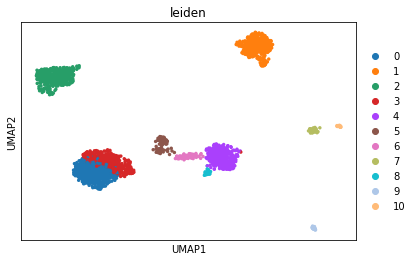

In [24]:
sc.pl.umap(adata, color='leiden')

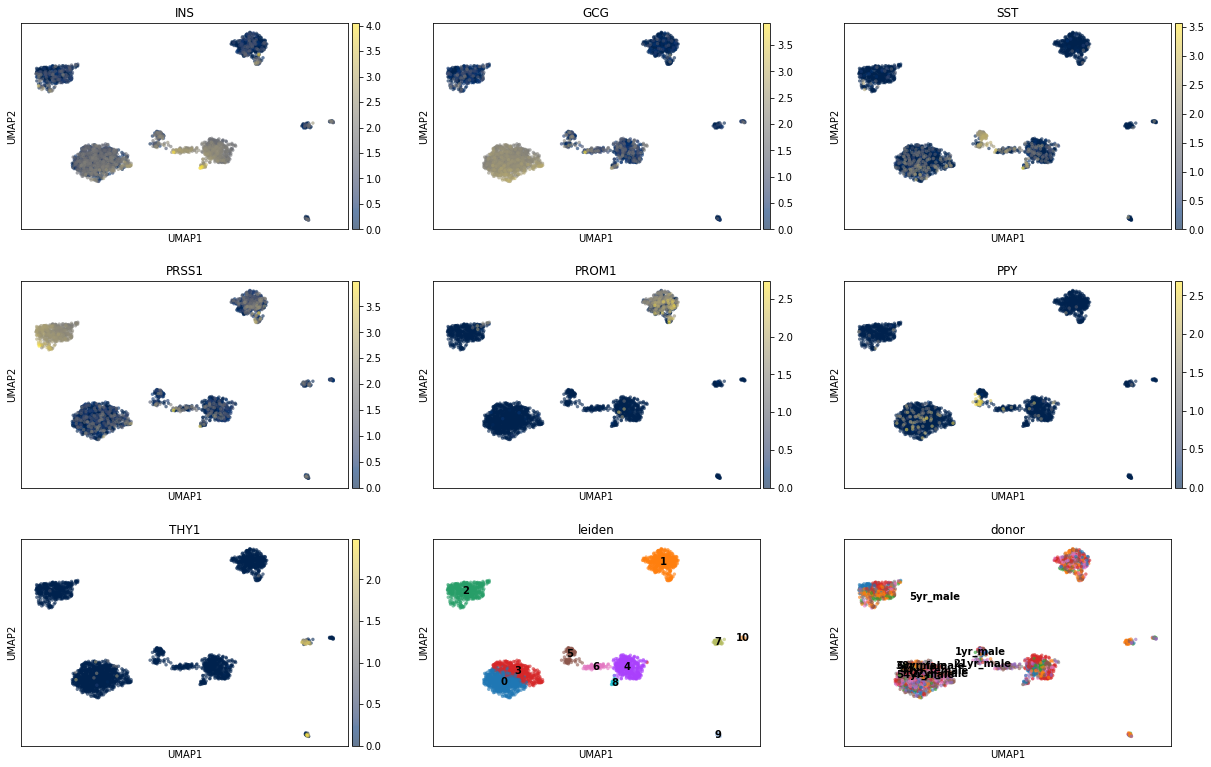

In [25]:
markers = ['INS', 'GCG', 'SST', 'PRSS1', 'PROM1', 'PPY', 'THY1']
sc.pl.umap(adata, color= markers + ['leiden', 'donor'], cmap='cividis', ncols=3, legend_loc='on data', alpha=0.6)

#  Identification of cell populations

In the original article, Enge et al describe seven cell types in their dataset, characterized by the expression of the following markers. 

* Beta cells: INS
* Alpha cells: GCG
* Delta cells: SST
* Acinar cells: PRSS1
* Ductal cells: PROM1
* PP cells: PPY
* Mesenchymal cells: THY1

We use the same markers to annotate the clusters obtained with Leiden. 

In [ ]:
# Dictionary with cluster-cell type annotation
name_dic = {'Beta cells': [2, 7], 'Alpha cells': [0, 4, 5], 'Delta cells': [6], 
           'Acinar cells': [3, 11], 'Ductal cells': [1], 'PP cells': [10], 'Mesenchymal cells': [8, 9]}
n_clusters = len(set(adata.obs['leiden']))
new_cluster_names = n_clusters*['Unknown']
inverse_dic = {}
for cell_type in name_dic.keys():
    for cluster in name_dic[cell_type]:
        inverse_dic[str(cluster)] = cell_type
        new_cluster_names[cluster] = cell_type

In [ ]:
# # Dictionary with cluster-cell type annotation
# name_dic = {'Beta cells': [0, 14], 'Alpha cells': [2, 5, 6, 7, 8, 12], 'Delta cells': [11], 
#            'Acinar cells': [3, 4], 'Ductal cells': [1, 9], 'PP cells': [10], 'Mesenchymal cells': [13]}
# n_clusters = len(set(adata.obs['leiden']))
# new_cluster_names = n_clusters*['Unknown']
# inverse_dic = {}
# for cell_type in name_dic.keys():
#     for cluster in name_dic[cell_type]:
#         inverse_dic[str(cluster)] = cell_type
#         new_cluster_names[cluster] = cell_type

In [ ]:
new_cluster_names

In [ ]:
adata.obs['cell_type'] = [inverse_dic[cluster] for cluster in adata.obs['leiden']]

In [ ]:
sc.pl.umap(adata, color='cell_type', legend_loc='on data')

## Supplementary figure: cell type annotation of the Enge dataset (Figure 1A from Enge paper)

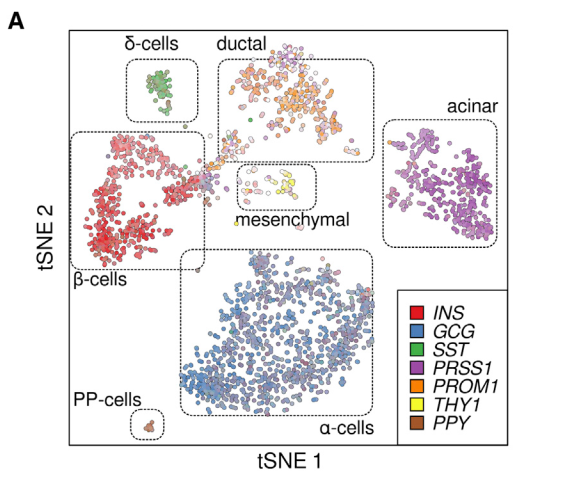

In [ ]:
markers

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,5))
sc.pl.umap(adata, color='cell_type', legend_loc='on data', palette=bold_and_vivid, alpha=0.6, legend_fontsize=12, legend_fontweight=10, ax=ax)
plt.savefig(f'../figs/processed_datasets/umaps/Enge_harmony.svg')

In [ ]:
dic_age = {1: '0-6', 5: '0-6', 6: '0-6', 21:'21-22' , 22:'21-22', 38:'38-54', 44:'38-54', 54:'38-54'}
adata.obs['age_group'] = [dic_age[age] for age in adata.obs['age']]

In [ ]:
dic_condition = {'0-6': 'Pediatric', '21-22': 'Young', '38-54': 'Old'}
adata.obs['condition'] = [dic_condition[age_group] for age_group in adata.obs['age_group']]

In [ ]:
adata.write('../../data/annDatas/annotated/Enge_annotated_harmony.h5ad')

# Only young and old (without pediatric individuals). 

In [44]:
adata = sc.read('../../data/anndatas/annotated/Enge_annotated_harmony.h5ad')

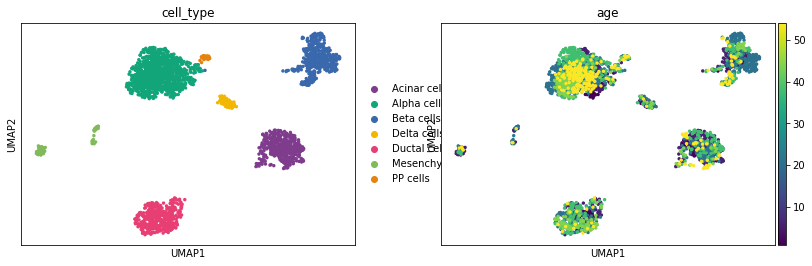

In [45]:
sc.pl.umap(adata, color=['cell_type', 'age'])

In [49]:
adata = adata[adata.obs['age_group'].isin(['21-22', '38-54'])]

In [53]:
adata

AnnData object with n_obs × n_vars = 1814 × 19642
    obs: 'age', 'sex', 'donor', 'n_genes', 'leiden', 'cell_type', 'age_group', 'condition'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'donor_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [51]:
sc.pp.highly_variable_genes(adata)

Trying to set attribute `.uns` of view, copying.


In [52]:
adata = preprocessing(adata, batch_correction='harmony', batch_category='donor')

2021-11-05 14:14:18,421 - harmonypy - INFO - Iteration 1 of 10
2021-11-05 14:14:19,354 - harmonypy - INFO - Iteration 2 of 10
2021-11-05 14:14:20,280 - harmonypy - INFO - Iteration 3 of 10
2021-11-05 14:14:21,068 - harmonypy - INFO - Iteration 4 of 10
2021-11-05 14:14:22,006 - harmonypy - INFO - Iteration 5 of 10
2021-11-05 14:14:22,776 - harmonypy - INFO - Iteration 6 of 10
2021-11-05 14:14:23,573 - harmonypy - INFO - Iteration 7 of 10
2021-11-05 14:14:24,322 - harmonypy - INFO - Iteration 8 of 10
2021-11-05 14:14:25,039 - harmonypy - INFO - Iteration 9 of 10
2021-11-05 14:14:25,833 - harmonypy - INFO - Converged after 9 iterations


In [56]:
sc.tl.umap(adata, min_dist=1)

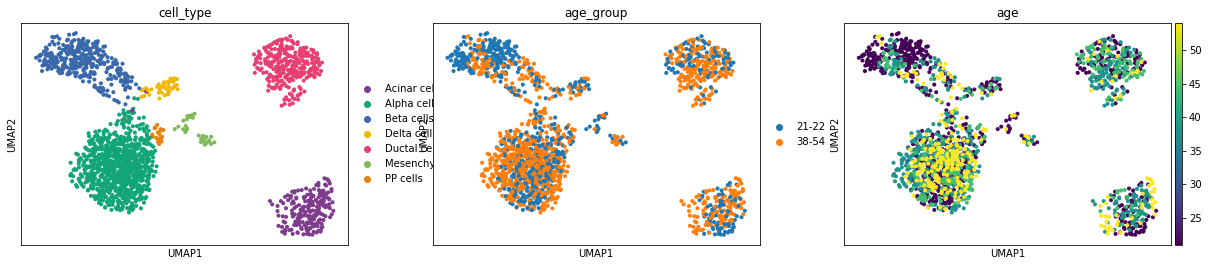

In [57]:
sc.pl.umap(adata, color=['cell_type', 'age_group', 'age'])

In [58]:
adata.write('../../data/anndatas/annotated/Enge_annotated_young_and_old.h5ad')